# T11 · SVR–GARCH CUSUM 을 ETF 20종에 적용 — 심층 시각화와 Track A·EDA 대비 정합성

> **지위**: Lee·Kim·Lee (2020) 방법의 **ETF 적용(sensitivity)** 이다. 원문 수치는 재현되지 않았으므로(Track B, METHOD_FIDELITY_UNRESOLVED)
> 이 노트북의 결과를 "원문 방법의 결과" 라고 부르지 않는다. 실제 매매·탐지 성능 수치가 아니다.

| 질문 | 절 |
|---|---|
| 70/30 분할에서 SVR–GARCH 가 어떤 분산·잔차를 만들고, 사후 CUSUM 은 무엇을 기각하나 | 1–3 |
| 같은 프레임워크를 이동창 20·30·60·120·252일(연) 로 돌리면 경보가 어디서, 얼마나 나오나 · 귀무 대비 | 4–5 |
| 경보 구간을 EDA 그래프(누적수익률·변동성·상관) 위에 그리면 무엇과 겹치나 | 6 |
| Track A 의 상관 전환(C3)·누적수익률 절대값 경계(P4)·P1·EDA 공통충격·고변동 국면과의 정합성 (원형 이동 귀무, BH) | 7 |
| 유의한 경보일 때 어떤 흐름이 겹치나 · 채권↔KOSPI 사례 · 연도 블록 | 8–10 |

**사전 고정 결정 (첫 실행 전, `audit` PLAN §5)**: 분할 = 앞 70% 적합(그 안 70/30 학습/검증, grid 27점) / 뒤 30% 검정 ·
임계값 = ETF 별 부트스트랩 95% (참고: N(0,1) MC, 점근 1.3397) · 1차 가족 = 정책 A · w=60 · 검정 구간 · {P1, 공통충격} · ±10일 ·
비양수 σ̂² 는 그날만 제외 · 시점 = 경보일 t (실시간), C3 는 확정일, P4 는 사후 확정일 · 고변동 = expanding 75% 분위 ·
"누적수익률 절대값 경계" = Track A P4 (h5/10/20, 양방향).

**실행**: `uv sync --extra dev --extra notebook --extra research` → (원시 시세: `ETF_RAW_DIR` 또는 FinanceDataReader 자동 수집, 종가 해시 검증)
→ `uv run jupyter execute notebooks/R2H_T11_svr_garch_cusum_etf.ipynb`. 결과표는 `research/svr_garch_cusum_etf/results/` (정본).

## 0. 환경 · 한글 폰트 · 데이터

In [1]:
# 경고 제어 모듈 — 한글 글리프 누락 경고를 오류로 바꿔 깨진 그림을 막는다
import warnings

# 파일 경로 처리
from pathlib import Path

# 날짜 축 눈금 포맷
import matplotlib.dates as mdates

# 그림 그리기
import matplotlib.pyplot as plt

# 수치 계산
import numpy as np

# 표 처리
import pandas as pd

# 폰트 등록 관리자
from matplotlib import font_manager

# 사각형 패치 (범례용)
from matplotlib.patches import Patch

# 노트북 안에 그림을 바로 표시
%matplotlib inline
# 규칙 9/18: 나눔고딕 .ttf 를 1순위로 등록 (.ttc 는 최후 후보)
KFONT_CANDIDATES = ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf", "C:/Windows/Fonts/malgun.ttf", "/Library/Fonts/AppleGothic.ttf"]
# 존재하는 첫 후보 경로를 고른다
KFONT = next((p for p in KFONT_CANDIDATES if Path(p).exists()), None)
# 한글 폰트가 없으면 깨진 그림을 만들지 않고 멈춘다 (strict)
assert KFONT, "한글 폰트 없음 — Ubuntu: sudo apt-get install fonts-nanum"
# matplotlib 폰트 목록에 등록
font_manager.fontManager.addfont(KFONT)
# 글자 단위 대체: 한글은 나눔고딕, 나눔고딕에 없는 그리스 문자(σ·ε·τ)는 DejaVu Sans
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=KFONT).get_name(), "DejaVu Sans"]
# 수식($...$) 글꼴은 DejaVu Sans (σ̂·ε̂ 등 기호가 정확히 놓임)
plt.rcParams["mathtext.fontset"] = "dejavusans"
# 음수 부호(−)가 □ 로 깨지지 않게 ASCII 하이픈 사용
plt.rcParams["axes.unicode_minus"] = False
# 그림 해상도·격자·테두리 기본값
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
# 위·오른쪽 테두리 제거
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
# 글리프 누락 경고가 나오면 즉시 오류 (한글 깨짐 0 보장)
warnings.filterwarnings("error", message=".*missing from font.*")
# 저장소 루트 (notebooks/ 에서 실행되든 루트에서 실행되든)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# 그림 저장 폴더 (README 가 이 그림을 쓴다)
FIG = ROOT / "docs" / "figures" / "svrgarch"
# 폴더 생성
FIG.mkdir(parents=True, exist_ok=True)
# 결과표 폴더 (오토런 산출물 = 정본)
RES = ROOT / "research" / "svr_garch_cusum_etf" / "results"
# 확인 출력
print("한글 폰트:", plt.rcParams["font.family"], "| 결과표:", RES.relative_to(ROOT))

한글 폰트: ['NanumGothic', 'DejaVu Sans'] | 결과표: research/svr_garch_cusum_etf/results


In [2]:
# 그림 저장 + 표시 도우미: 메타데이터 없는 PNG (실행마다 바이트 동일)
def show(fig, name):
    # 여백을 줄여 저장
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", metadata={"Software": None})
    # 노트북에 표시
    plt.show()


# 오토런 모듈 — 결과표가 없으면 전체 파이프라인을 다시 돌린다
from r2h.svrgarch_etf import run

# 사건 원천(Track A·EDA 공개표, sha256 검증)과 고변동 판정
from r2h.svrgarch_etf.events import event_table, family_dates, high_vol_flag

# 이동창 통계 함수 (그림에서 다시 계산할 때 사용)
from r2h.svrgarch_etf.rolling import WINDOWS

# 로컬 상태 파일 (일별 수익률·잔차 — 저장소에 올리지 않음)
STATE = ROOT / "outputs" / "cache" / "t11_state.npz"
# 상태나 결과표가 없으면 오토런 실행 (원시 시세는 ETF_RAW_DIR 또는 FinanceDataReader)
if not STATE.exists() or not (RES / "run_manifest.json").exists():
    # 파이프라인 실행 (약 2–3분)
    run(RES)
# 상태 파일 읽기
st = np.load(STATE, allow_pickle=False)
# 공통 거래일 index 복원
idx = pd.DatetimeIndex(st["dates"].astype("datetime64[ns]"))
# ETF 목록
TICKERS = [str(t) for t in st["tickers"]]
# 일별 % 로그수익률 (100·Δlog)
R = pd.DataFrame({t: st[f"r__{t}"] for t in TICKERS}, index=idx)
# 결과표 읽기 (ticker 는 문자열로 — 069500 의 선행 0 보존)
rd = lambda name: pd.read_csv(RES / name, dtype={"ticker": str})
# 적합 요약
fit = rd("fit_summary.csv").set_index("ticker")
# 사후 검정 (검정 구간 30%)
full = rd("fullsample_tests.csv")
# 임계값
crit = rd("critical_values.csv")
# 경보 에피소드
eps = rd("alarm_episodes.csv")
# 귀무 오탐률
nul = rd("null_alarm_rate.csv")
# 사건 근접 지표
ov = rd("overlap_metrics.csv")
# 흐름 겹침
flows = rd("episode_flows.csv")
# 연도 블록
years = rd("yearly_blocks.csv")
# 이동창 통계량 (날짜 × ticker|잔차|창)
roll = pd.read_csv(RES / "rolling_stats.csv.gz", index_col=0, parse_dates=True)
# ETF 이름표 (한글 이름)
NAMES = pd.read_csv(ROOT / "research/svr_garch_cusum_etf/reference_close_sha256.csv", dtype=str).set_index("ticker")["name"].to_dict()
# 라벨 함수: "069500 KODEX 200"
lab = lambda t: f"{t} {NAMES[t]}"
# 비교 사건표 (P1·P4·공통충격·C3·고변동)
events = event_table(pd.Series(np.exp(np.cumsum(np.r_[0, R["069500"].to_numpy() / 100])) * 100, index=idx.insert(0, idx[0] - pd.Timedelta(days=1))))
# 적합/검정 경계일 (거의 모든 ETF 가 같은 날)
SPLIT = pd.Timestamp(fit["split_date"].mode()[0])
# 확인 출력
print(len(TICKERS), "ETF ×", len(idx), "거래일 | 분할일", SPLIT.date(), "| 사건", events.family.value_counts().to_dict())

20 ETF × 1902 거래일 | 분할일 2024-05-29 | 사건 {'P4_h5': 706, 'P1': 618, 'P4_h10': 481, 'P4_h20': 391, 'COMMON': 40, 'C3': 35, 'HIVOL': 34}


## 1. 70/30 분할 — 무엇으로 배우고 무엇으로 검정하나

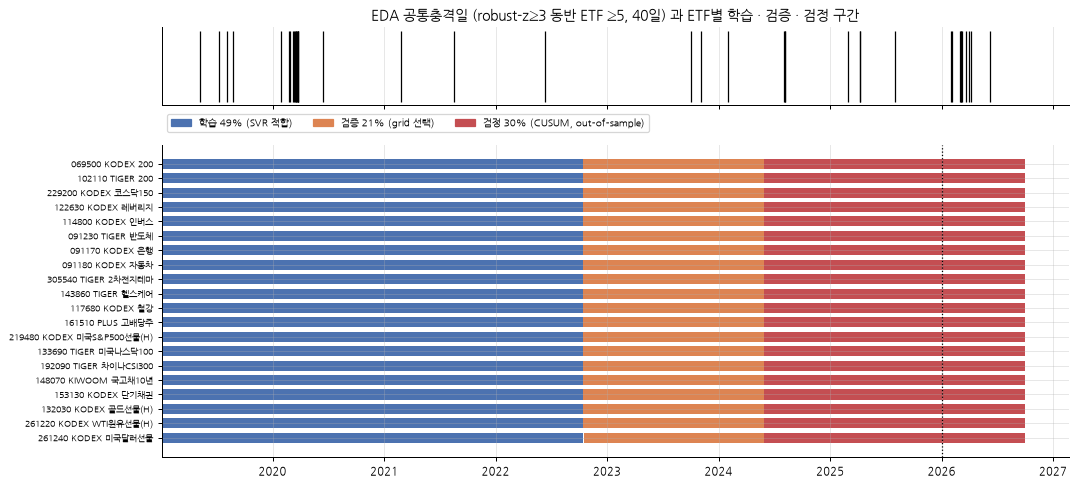

,C,paper_gamma_squared,epsilon,val_mae,split_date
ticker,,,,,
069500 KODEX 200,1,0.5,0.1,0.304163,2024-05-29
102110 TIGER 200,100,1.0,0.1,0.302897,2024-05-29
229200 KODEX 코스닥150,10,0.5,0.1,0.984337,2024-05-29
122630 KODEX 레버리지,10,1.0,0.1,1.188160,2024-05-29
114800 KODEX 인버스,10,0.5,0.1,0.332357,2024-05-29
091230 TIGER 반도체,1,1.0,0.1,0.827355,2024-05-29
091170 KODEX 은행,1,1.0,0.1,0.710269,2024-05-29
091180 KODEX 자동차,10,1.0,0.1,0.570272,2024-05-29
305540 TIGER 2차전지테마,10,1.0,0.1,2.210600,2024-05-29


In [3]:
# 그림 크기: ETF 20개 줄 + 위쪽 공통충격 막대
fig, ax = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 4]})
# 공통충격일(유니버스) 날짜
cs = family_dates(events, "COMMON", "069500")
# 위 패널: 공통충격일을 세로 막대로
ax[0].vlines(cs, 0, 1, color="k", lw=1)
# 위 패널 제목
ax[0].set_title("EDA 공통충격일 (robust-z≥3 동반 ETF ≥5, 40일) 과 ETF별 학습 · 검증 · 검정 구간")
# 위 패널 y 축 숨김
ax[0].set_yticks([])
# ETF 마다 한 줄씩
for i, t in enumerate(TICKERS):
    # 그 ETF 의 유효 수익률 날짜
    d = R[t].dropna().index
    # 학습/검증/검정 경계 위치
    n_tr, n_fit = int(fit.loc[t, "n_train"]), int(fit.loc[t, "n_train"] + fit.loc[t, "n_validation"])
    # 학습 구간 막대 (파랑)
    ax[1].barh(i, d[n_tr - 1] - d[0], left=d[0], color="#4C72B0", height=0.7)
    # 검증 구간 막대 (주황)
    ax[1].barh(i, d[n_fit - 1] - d[n_tr], left=d[n_tr], color="#DD8452", height=0.7)
    # 검정 구간 막대 (빨강)
    ax[1].barh(i, d[-1] - d[n_fit], left=d[n_fit], color="#C44E52", height=0.7)
# y 축 = ETF 이름
ax[1].set_yticks(range(len(TICKERS)), [lab(t) for t in TICKERS], fontsize=7)
# 위에서부터 첫 ETF
ax[1].invert_yaxis()
# 범례 (학습/검증/검정)
ax[0].legend(handles=[Patch(color="#4C72B0", label="학습 49% (SVR 적합)"), Patch(color="#DD8452", label="검증 21% (grid 선택)"), Patch(color="#C44E52", label="검정 30% (CUSUM, out-of-sample)")], loc="upper left", fontsize=8, ncol=3, bbox_to_anchor=(0, -0.05))
# 2026 시작 표시
ax[1].axvline(pd.Timestamp("2026-01-01"), color="k", ls=":", lw=1)
# 저장·표시
show(fig, "01_split_timeline")
# 선택된 SVR 파라미터 분포 표
fit[["C", "paper_gamma_squared", "epsilon", "val_mae", "split_date"]].rename(index=lab)

**해석**

- 수익률 1,902개 → **학습 932 · 검증 399 · 검정 571** (분할일 2024-05-29, 261240 만 DQ 2일 제외로 05-30). 검정 구간에는 2026 고변동 국면과 EDA 공통충격일 40일 중 **17일**이 들어 있다.
- 이 70/30 은 원문(전체 50/50 → 적합구간 내부 70/30)과 다른 **T11 프로토콜**이다. 검정 구간이 '이미 아는 2026 국면' 을 포함하므로, 검정 구간 기각은 새 발견이 아니라 그 국면의 재확인일 수 있다.
- grid 선택: ε 는 20종 모두 **0.1 (grid 하한)**, C 는 1 (10종)·10 (9종)·100 (1종), γ² 는 1.0 (12종)·0.5 (6종)·0.1 (2종). ε 가 grid 경계에 붙었다는 것은 원문이 범위만 준 grid(ASSUMPTION)가 좁을 수 있다는 신호다 — 결과를 본 뒤 grid 를 넓히지는 않았다.

## 2. 한 종목 해부 — 069500 KODEX 200: 수익률 → proxy·σ̂² → 잔차² → CUSUM 경로

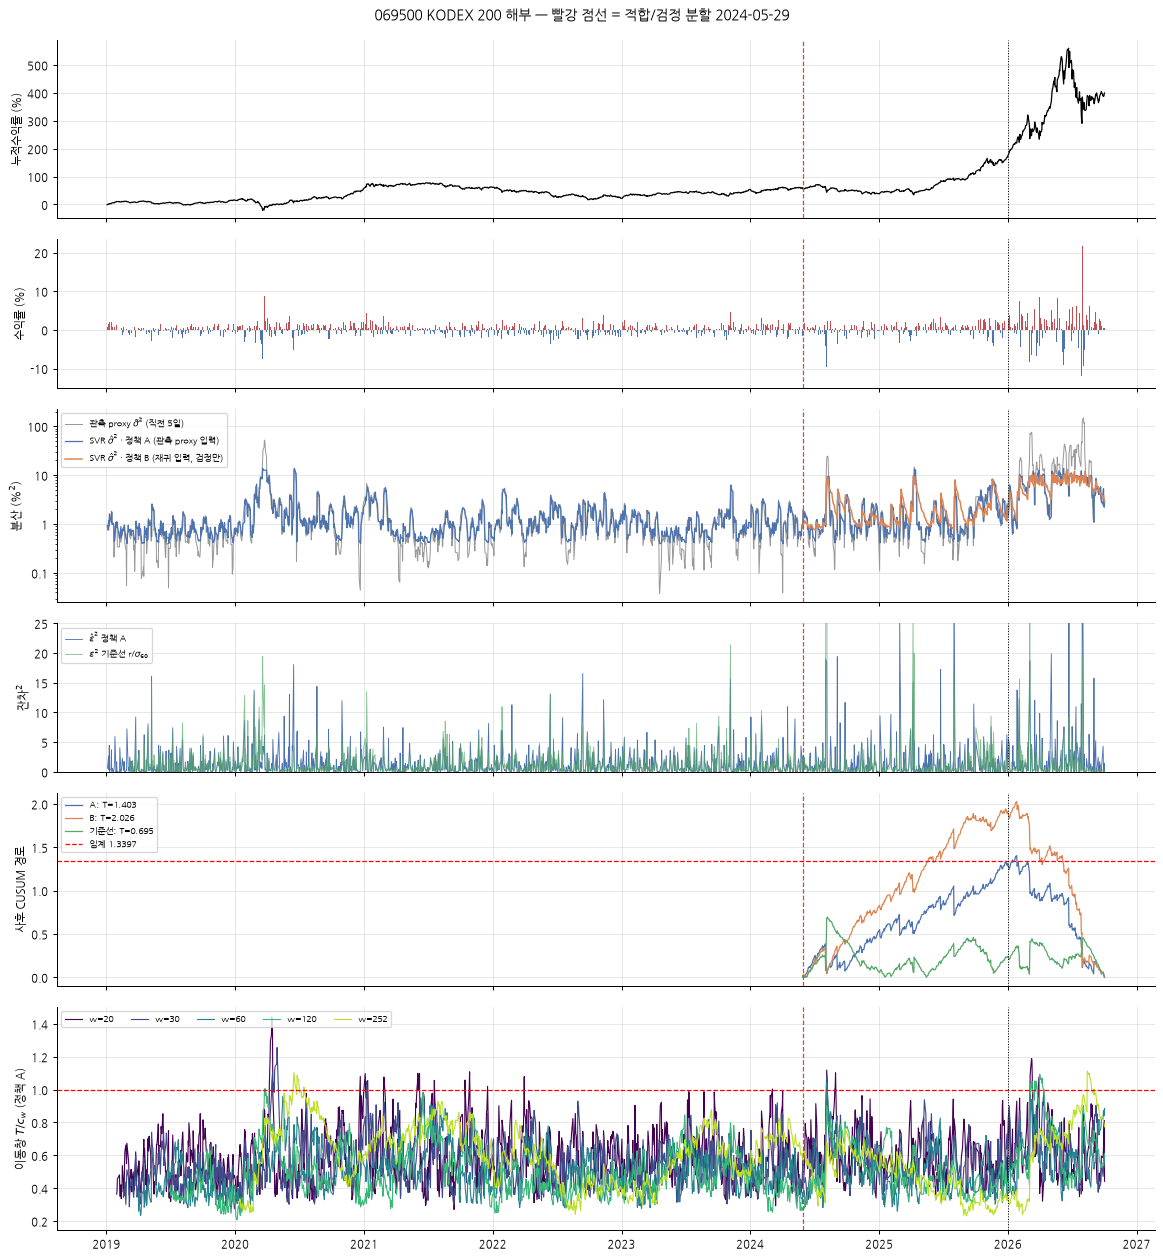

In [4]:
# 해부할 종목
T0 = "069500"
# 날짜 index
d = idx
# 그 종목 수익률
r0 = R[T0]
# 관측 proxy σ̃² (직전 5일 제곱평균)
proxy = pd.Series(st[f"proxy__{T0}"], index=d)
# 정책 A σ̂² (관측 proxy 입력)
va = pd.Series(st[f"varA__{T0}"], index=d)
# 정책 B σ̂² (검정 구간 재귀 입력)
vb = pd.Series(st[f"varB__{T0}"], index=d)
# 정책 A 잔차
ea = pd.Series(st[f"res__{T0}__svrA"], index=d)
# 기준선 잔차 r/σ60
eb = pd.Series(st[f"res__{T0}__base"], index=d)
# 6단 그림 (x 축 공유)
fig, ax = plt.subplots(6, 1, figsize=(13, 14), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1.3, 1, 1.3, 1.5]})
# (1) 누적수익률 = exp(Σr/100) − 1
ax[0].plot(d, (np.exp(r0.cumsum() / 100) - 1) * 100, color="k", lw=1)
# (1) 축 이름
ax[0].set_ylabel("누적수익률 (%)")
# (2) 일간 수익률 막대
ax[1].bar(d, r0, width=1.5, color=np.where(r0 > 0, "#C44E52", "#4C72B0"))
# (2) 축 이름
ax[1].set_ylabel("수익률 (%)")
# (3) proxy (회색)
ax[2].plot(d, proxy, color="0.6", lw=0.8, label=r"관측 proxy $\tilde{\sigma}^2$ (직전 5일)")
# (3) 정책 A σ̂²
ax[2].plot(d, va, color="#4C72B0", lw=1, label=r"SVR $\hat{\sigma}^2$ · 정책 A (관측 proxy 입력)")
# (3) 정책 B σ̂² (검정 구간)
ax[2].plot(d, vb, color="#DD8452", lw=1.2, label=r"SVR $\hat{\sigma}^2$ · 정책 B (재귀 입력, 검정만)")
# (3) 로그 축 — 2026 고변동을 같이 보기 위해
ax[2].set_yscale("log")
# (3) 로그축 눈금을 일반 숫자로 (수식 글꼴의 음수 기호 깨짐 방지)
ax[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
# (3) 축 이름·범례
ax[2].set_ylabel(r"분산 (%$^2$)"); ax[2].legend(fontsize=7, loc="upper left")
# (4) 잔차 제곱 — 정책 A 와 기준선
ax[3].plot(d, ea**2, color="#4C72B0", lw=0.7, label=r"$\hat{\varepsilon}^2$ 정책 A")
# (4) 기준선 잔차 제곱
ax[3].plot(d, eb**2, color="#55A868", lw=0.7, alpha=0.7, label=r"$\varepsilon^2$ 기준선 r/$\sigma_{60}$")
# (4) 축 범위·이름·범례
ax[3].set_ylim(0, 25); ax[3].set_ylabel(r"잔차$^2$"); ax[3].legend(fontsize=7, loc="upper left")
# (5) 검정 구간 사후 CUSUM 경로 (정규화): 정책 A, B, 기준선
for name, e, c in [("A", ea, "#4C72B0"), ("B", pd.Series(st[f"res__{T0}__svrB"], index=d), "#DD8452"), ("기준선", eb, "#55A868")]:
    # 검정 구간 잔차만
    x = e[d >= SPLIT].dropna()
    # τ̂ (원문 분모 n)
    tau = np.sqrt(np.mean(x**4) - np.mean(x**2) ** 2)
    # 정규화 경로 |D_k| / (√n τ̂)
    path = np.abs(np.cumsum(x**2) - np.arange(1, len(x) + 1) / len(x) * np.sum(x**2)) / (np.sqrt(len(x)) * tau)
    # 경로 그리기 (최대값 = 통계량)
    ax[4].plot(x.index, path, color=c, lw=1, label=f"{name}: T={path.max():.3f}")
# (5) 5% 임계값
ax[4].axhline(1.3397, color="r", ls="--", lw=1, label="임계 1.3397")
# (5) 축 이름·범례
ax[4].set_ylabel("사후 CUSUM 경로"); ax[4].legend(fontsize=7, loc="upper left")
# (6) 이동창 통계량 / 부트스트랩 임계값 (1 이상 = 경보)
for w, c in zip(WINDOWS, plt.cm.viridis(np.linspace(0, 0.9, len(WINDOWS))), strict=True):
    # 그 창의 정책 A 임계값
    cw = crit.query("ticker == @T0 and rtype == 'svrA' and window == @w")["c_bootstrap"].iloc[0]
    # 비율 곡선
    ax[5].plot(roll.index, roll[f"{T0}|svrA|{w}"] / cw, color=c, lw=0.9, label=f"w={w}")
# (6) 경보 기준선
ax[5].axhline(1, color="r", ls="--", lw=1)
# (6) 축 이름·범례
ax[5].set_ylabel(r"이동창 $T/c_w$ (정책 A)"); ax[5].legend(fontsize=7, ncol=5, loc="upper left")
# 모든 패널에 분할일·2026 시작 표시
for a in ax:
    # 분할일 (빨강 점선)
    a.axvline(SPLIT, color="#C44E52", ls="--", lw=1)
    # 2026 시작 (검정 점선)
    a.axvline(pd.Timestamp("2026-01-01"), color="k", ls=":", lw=0.8)
# 전체 제목
fig.suptitle(f"{lab(T0)} 해부 — 빨강 점선 = 적합/검정 분할 {SPLIT.date()}", y=0.995)
# 여백 정리
fig.tight_layout()
# 저장·표시
show(fig, "02_anatomy_069500")

**해석**

- (3) 정책 A 의 σ̂² 는 직전 5일 proxy σ̃² 를 거의 그대로 따라간다. 그래서 변동성이 오르면 분모도 바로 오르고, (4) 잔차² 의 뭉침이 줄어든다.
- (5) 검정 구간 사후 CUSUM: **정책 A T=1.403 (기각, k̂ 2026-01-26) · 정책 B T=2.026 (기각) · 기준선 T=0.695 (비기각)**. 같은 데이터에서 '원문에 없는 테스트 분산 입력 규칙' 하나로 판정이 갈린다 (Track B 진단과 같음).
- (6) 정책 A 이동창(창 5종 중 하나라도) T/c_w ≥ 1 인 날은 **2020-04·06 (24일)**, 2021 년 산발(16일), **2024-08 (5일)**, **2026-03~04 (20일)**, 2026-08 (9일) 에 몰리고, 나머지 기간은 대부분 1 아래다.

## 3. 20종 사후 검정 (검정 구간 30%) — 정책 A · B · 기준선

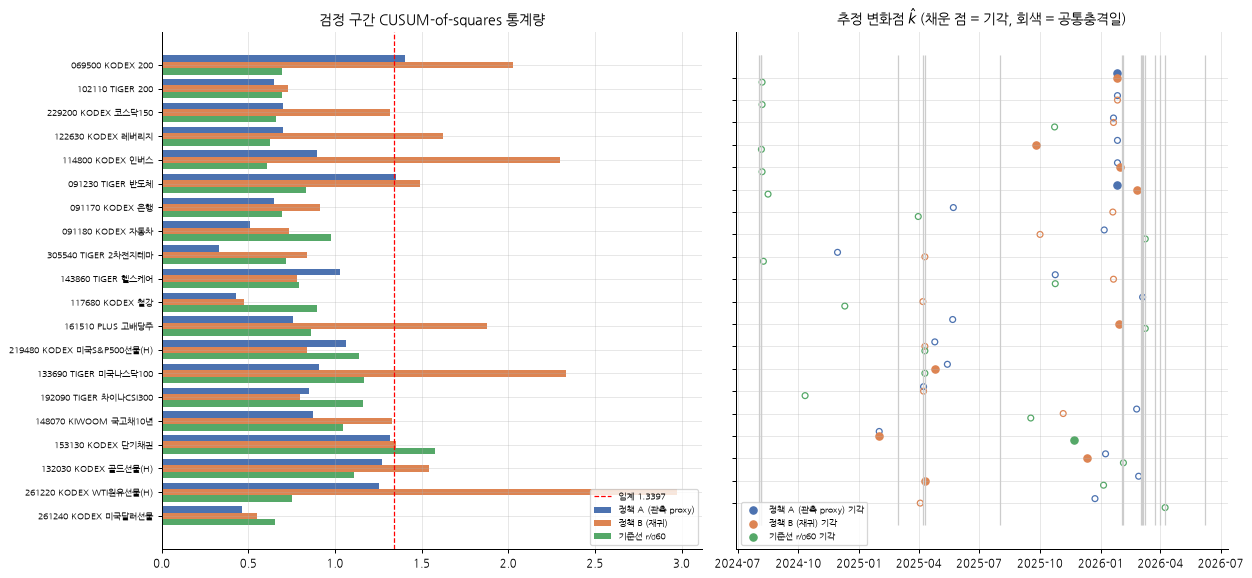

,검정,기각,실패
policy,,,
A,20,2,0
B,20,9,0
base,20,1,0


In [5]:
# 통계량 표: 행 = ETF, 열 = 정책
T = full.pivot(index="ticker", columns="policy", values="T").loc[TICKERS]
# 변화점 날짜 표
K = full.pivot(index="ticker", columns="policy", values="khat_date").loc[TICKERS]
# 2단 그림: 막대 + 변화점 타임라인
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
# 막대 위치
y = np.arange(len(TICKERS))
# 정책별 색
COL = {"A": "#4C72B0", "B": "#DD8452", "base": "#55A868"}
# 정책별 한글 이름
PNAME = {"A": "정책 A (관측 proxy)", "B": "정책 B (재귀)", "base": "기준선 r/σ60"}
# 정책마다 가로 막대
for k, pol in enumerate(["A", "B", "base"]):
    # 막대 그리기
    ax[0].barh(y + (k - 1) * 0.27, T[pol], 0.27, color=COL[pol], label=PNAME[pol])
# 5% 임계값
ax[0].axvline(1.3397, color="r", ls="--", lw=1, label="임계 1.3397")
# y 축 이름
ax[0].set_yticks(y, [lab(t) for t in TICKERS], fontsize=7); ax[0].invert_yaxis()
# 제목·범례
ax[0].set_title("검정 구간 CUSUM-of-squares 통계량"); ax[0].legend(fontsize=7, loc="lower right")
# 변화점 날짜 점 (정책별)
for k, pol in enumerate(["A", "B", "base"]):
    # 기각된 것은 채운 점, 아니면 빈 점
    rej = full.set_index(["ticker", "policy"]).loc[[(t, pol) for t in TICKERS], "reject"].to_numpy().astype(bool)
    # 날짜 변환
    kd = pd.to_datetime(K[pol])
    # 비기각
    ax[1].scatter(kd[~rej], y[~rej] + (k - 1) * 0.2, s=22, facecolors="none", edgecolors=COL[pol])
    # 기각
    ax[1].scatter(kd[rej], y[rej] + (k - 1) * 0.2, s=34, color=COL[pol], label=f"{PNAME[pol]} 기각")
# 공통충격일 날짜
csd = family_dates(events, "COMMON", "069500")
# 검정 구간 안의 공통충격일만 회색 세로선
ax[1].vlines(csd[csd >= SPLIT], -1, len(TICKERS), color="0.8", lw=1)
# y 축 이름 숨김·정렬
ax[1].set_yticks(y, []); ax[1].invert_yaxis()
# 제목·범례
ax[1].set_title(r"추정 변화점 $\hat{k}$ (채운 점 = 기각, 회색 = 공통충격일)"); ax[1].legend(fontsize=7, loc="lower left")
# 날짜 눈금 형식
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
# 여백
fig.tight_layout()
# 저장·표시
show(fig, "03_fullsample_tests")
# 기각 수 요약
full.groupby("policy").agg(검정=("T", "size"), 기각=("reject", "sum"), 실패=("status", lambda s: (s != "ok").sum()))

**해석**

- 기각 수: **정책 A 2/20** (069500·091230) · **정책 B 9/20** · **기준선 1/20** (153130). 분산 입력 규칙에 따라 기각 수가 4.5배 달라진다 → ETF 결과도 **정책 A·B 를 병기하는 민감도 결과**로만 쓴다.
- k̂ 는 정책 A 에서 **2026-01 에 8종**, 정책 B 는 2026-01 (7종)·2025-04 (7종), 기준선은 2024-08 (6종)에 모인다. 회색 공통충격일과 같은 시기다 — 검출된 '변화' 는 대부분 알려진 고변동 국면의 시작이다.

## 4. 같은 프레임워크를 이동창 20·30·60·120·252일(연) 로 — ETF × 시간 경보 지도

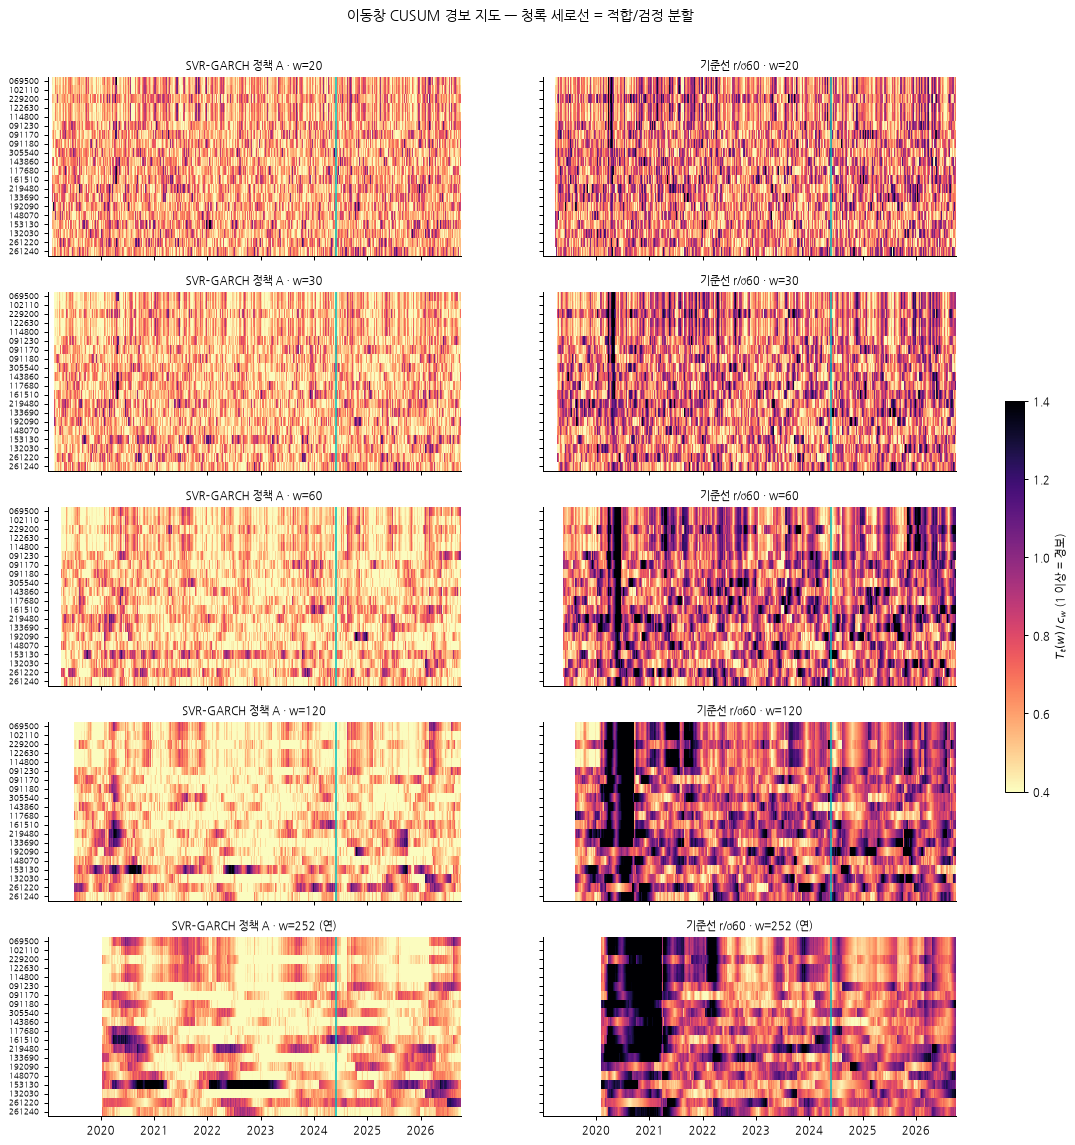

In [6]:
# 5행(창) × 2열(정책 A, 기준선) 히트맵
fig, ax = plt.subplots(len(WINDOWS), 2, figsize=(14, 15), sharex=True, sharey=True)
# 색 범위: T/c_w 의 0.4~1.4 (1 이상 = 경보)
norm = plt.Normalize(0.4, 1.4)
# 창마다
for i, w in enumerate(WINDOWS):
    # 잔차 종류마다
    for j, (rt, title) in enumerate([("svrA", "SVR–GARCH 정책 A"), ("base", "기준선 r/σ60")]):
        # 그 창의 ETF 별 임계값
        cw = crit.query("rtype == @rt and window == @w").set_index("ticker")["c_bootstrap"]
        # ETF × 날짜 행렬 (T / c_w)
        M = np.vstack([roll[f"{t}|{rt}|{w}"].to_numpy() / cw[t] for t in TICKERS])
        # 히트맵
        im = ax[i, j].imshow(M, aspect="auto", cmap="magma_r", norm=norm, interpolation="nearest", extent=[mdates.date2num(roll.index[0]), mdates.date2num(roll.index[-1]), len(TICKERS), 0])
        # 분할일
        ax[i, j].axvline(mdates.date2num(SPLIT), color="c", lw=1.2)
        # 제목 (창·잔차)
        ax[i, j].set_title(f"{title} · w={w}{' (연)' if w == 252 else ''}", fontsize=9)
        # 격자 끄기
        ax[i, j].grid(False)
    # 왼쪽 열에 ETF 이름
    ax[i, 0].set_yticks(np.arange(len(TICKERS)) + 0.5, TICKERS, fontsize=6)
# 날짜 축
ax[-1, 0].xaxis_date(); ax[-1, 1].xaxis_date()
# 색 막대
fig.colorbar(im, ax=ax, fraction=0.02, label=r"$T_t(w)\,/\,c_w$ (1 이상 = 경보)")
# 전체 제목
fig.suptitle("이동창 CUSUM 경보 지도 — 청록 세로선 = 적합/검정 분할", y=0.93)
# 저장·표시
show(fig, "04_rolling_heatmaps")

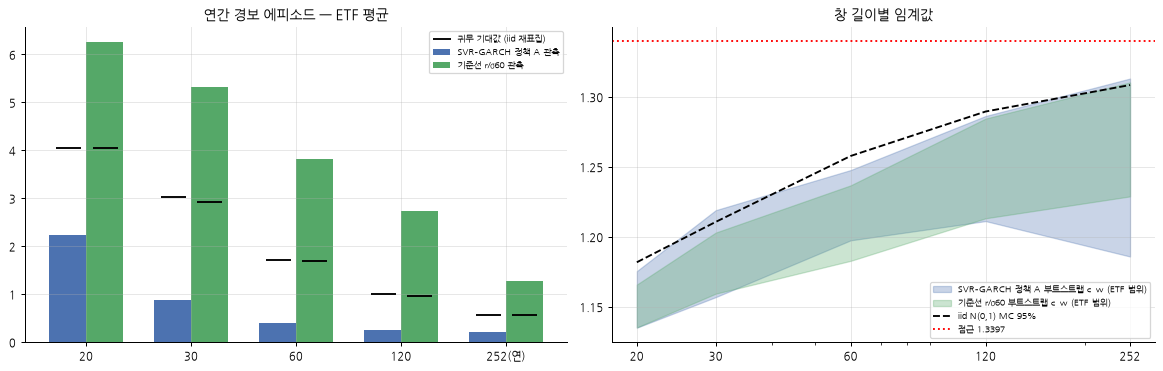

observed_episodes_per_year  null_episodes_per_year  c_bootstrap
rtype window                                                                 
base  20                            6.26                    4.04         1.15
      30                            5.31                    2.93         1.18
      60                            3.82                    1.70         1.22
      120                           2.73                    0.97         1.25
      252                           1.28                    0.57         1.27
svrA  20                            2.23                    4.05         1.16
      30                            0.87                    3.02         1.18
      60                            0.39                    1.71         1.22
      120                           0.25                    0.99         1.26
      252                           0.21                    0.56         1.28

In [7]:
# 창 길이별 관측 vs 귀무 연간 경보 에피소드
g = nul.groupby(["rtype", "window"])[["observed_episodes_per_year", "null_episodes_per_year", "c_bootstrap"]].agg(["mean", "min", "max"])
# 2단 그림
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
# 잔차 종류마다
for k, (rt, c, nm) in enumerate([("svrA", "#4C72B0", "SVR–GARCH 정책 A"), ("base", "#55A868", "기준선 r/σ60")]):
    # x 위치
    x = np.arange(len(WINDOWS)) + (k - 0.5) * 0.35
    # 관측 평균 막대
    ax[0].bar(x, g.loc[rt][("observed_episodes_per_year", "mean")], 0.35, color=c, label=f"{nm} 관측")
    # 귀무 평균 (검정 가로 눈금)
    ax[0].scatter(x, g.loc[rt][("null_episodes_per_year", "mean")], marker="_", s=400, color="k", zorder=3)
    # 임계값 범위 (ETF 간 최소~최대)
    ax[1].fill_between(WINDOWS, g.loc[rt][("c_bootstrap", "min")], g.loc[rt][("c_bootstrap", "max")], color=c, alpha=0.3, label=f"{nm} 부트스트랩 c_w (ETF 범위)")
# 귀무 표시 범례용
ax[0].scatter([], [], marker="_", s=200, color="k", label="귀무 기대값 (iid 재표집)")
# x 축 눈금
ax[0].set_xticks(np.arange(len(WINDOWS)), [f"{w}{'(연)' if w == 252 else ''}" for w in WINDOWS])
# 제목·범례
ax[0].set_title("연간 경보 에피소드 — ETF 평균"); ax[0].legend(fontsize=7)
# N(0,1) 임계값
ax[1].plot(WINDOWS, crit.groupby("window")["c_normal"].first(), "k--", label="iid N(0,1) MC 95%")
# 점근 임계값
ax[1].axhline(1.3397, color="r", ls=":", label="점근 1.3397")
# 축·범례
ax[1].set_xscale("log"); ax[1].set_xticks(WINDOWS, WINDOWS); ax[1].set_title("창 길이별 임계값"); ax[1].legend(fontsize=7)
# 로그축 보조 눈금 라벨 숨김
ax[1].xaxis.set_minor_formatter(plt.NullFormatter())
# 여백
fig.tight_layout()
# 저장·표시
show(fig, "05_window_vs_null")
# 수치 표
g.xs("mean", axis=1, level=1).round(2)

**해석**

- **기준선 r/σ60**: 모든 창에서 관측 경보가 iid 기준값보다 많다 (w=60 연 3.82 vs 1.70, **20종 모두 초과**). 60일 표준화로는 변동성 뭉침이 남아 CUSUM 이 변동성 국면 변화를 잡는다 (히트맵의 2020 검은 띠).
- **SVR–GARCH 정책 A**: 모든 창에서 관측이 iid 기준값보다 **적다** (w=60 연 0.39 vs 1.71, 초과 **0/20** 종). 직전 5일 proxy 입력이 분산 변화를 흡수해 잔차 제곱이 iid 보다도 평탄해진다 — 이 설정의 CUSUM 은 사실상 검정력이 없다.
- 주의: 이 '귀무' 는 적합 구간 잔차를 **iid 재표집**한 값으로, 창 단위 5% 를 연간 에피소드로 환산한 기준선이다. 변동성 군집 아래의 오탐률 보정이 아니다 (블록 부트스트랩이 필요 — 후속).
- 창이 길수록 경보는 줄고 임계값은 오른다. 짧은 창(w=20)의 유한표본 95% 임계값은 1.14–1.18 로 점근값 1.3397 보다 훨씬 낮다 → 짧은 창에 점근 임계값을 쓰면 지나치게 보수적이다.

## 5–6. 경보 구간을 EDA 그래프 위에 — 누적수익률 · 60일 변동성 · 60일 상관(vs 069500)

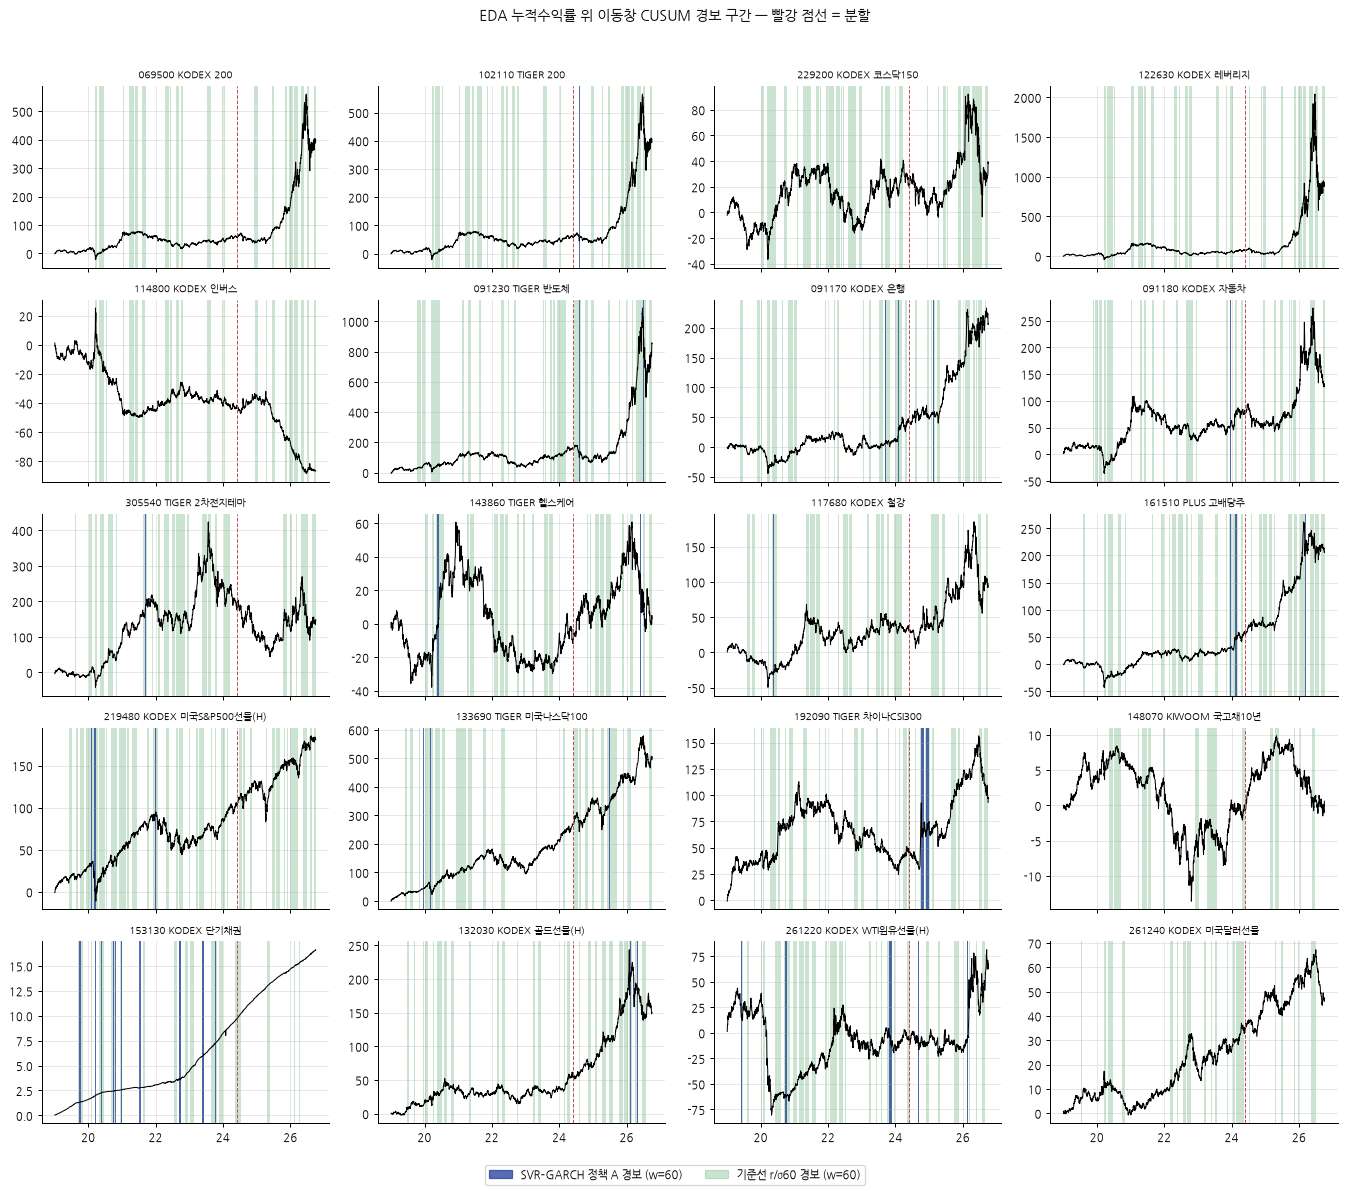

In [8]:
# 20종 small multiples: 누적수익률 + 경보 구간 (w=60: 정책 A 파랑, 기준선 초록)
fig, axs = plt.subplots(5, 4, figsize=(15, 13), sharex=True)
# ETF 마다 한 칸
for a, t in zip(axs.ravel(), TICKERS, strict=True):
    # 누적수익률 (%)
    a.plot(idx, (np.exp(R[t].fillna(0).cumsum() / 100) - 1) * 100, color="k", lw=0.8)
    # 두 잔차 종류의 w=60 에피소드 음영
    for rt, c, al in [("base", "#55A868", 0.3), ("svrA", "#1f3b99", 0.75)]:
        # 그 ETF·창의 에피소드 (정책 A 를 위에 진하게)
        for e in eps.query("ticker == @t and rtype == @rt and window == 60 and mask == 'none'").itertuples():
            # 시작~끝 음영
            a.axvspan(pd.Timestamp(e.start), pd.Timestamp(e.end) + pd.Timedelta(days=3), color=c, alpha=al, lw=0)
    # 분할일
    a.axvline(SPLIT, color="#C44E52", ls="--", lw=0.8)
    # 제목
    a.set_title(lab(t), fontsize=8)
    # 날짜 눈금 연도만
    a.xaxis.set_major_locator(mdates.YearLocator(2)); a.xaxis.set_major_formatter(mdates.DateFormatter("%y"))
# 범례
fig.legend(handles=[Patch(color="#1f3b99", alpha=0.75, label="SVR–GARCH 정책 A 경보 (w=60)"), Patch(color="#55A868", alpha=0.3, label="기준선 r/σ60 경보 (w=60)")], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
# 전체 제목
fig.suptitle("EDA 누적수익률 위 이동창 CUSUM 경보 구간 — 빨강 점선 = 분할", y=1.0)
# 여백 (아래 범례 자리)
fig.tight_layout(rect=(0, 0.02, 1, 0.98))
# 저장·표시
show(fig, "06a_eda_cumret_intervals")

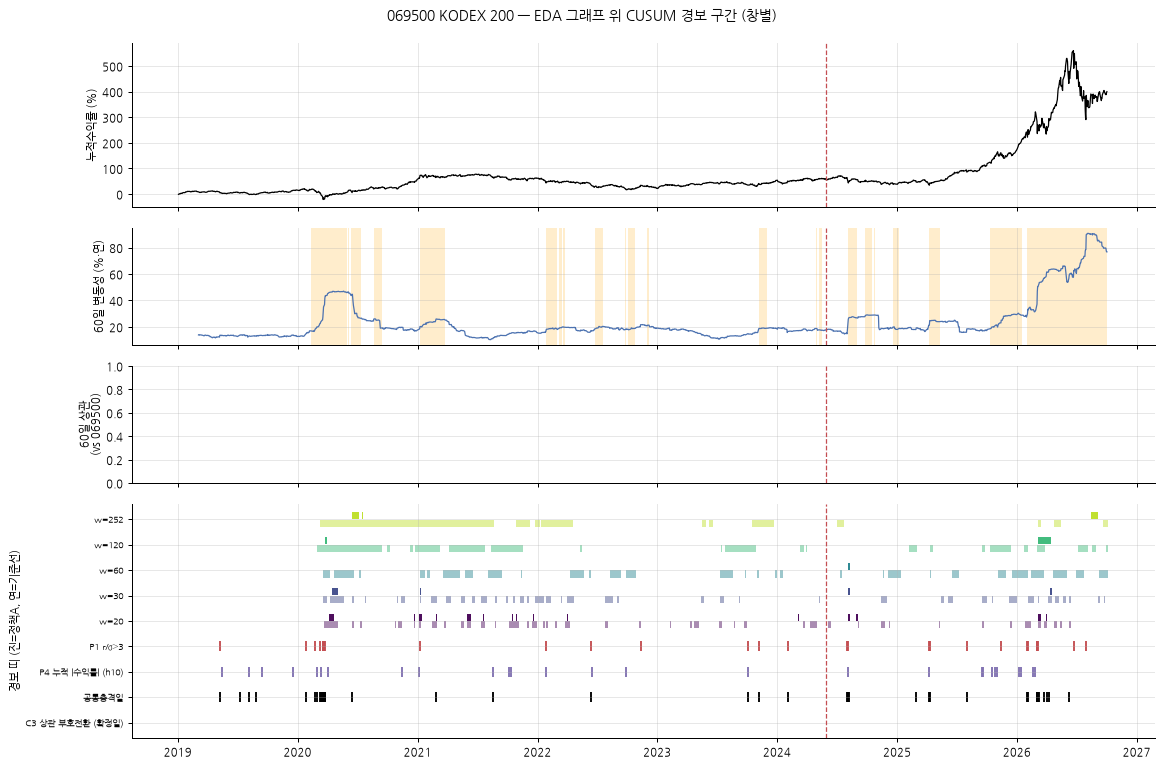

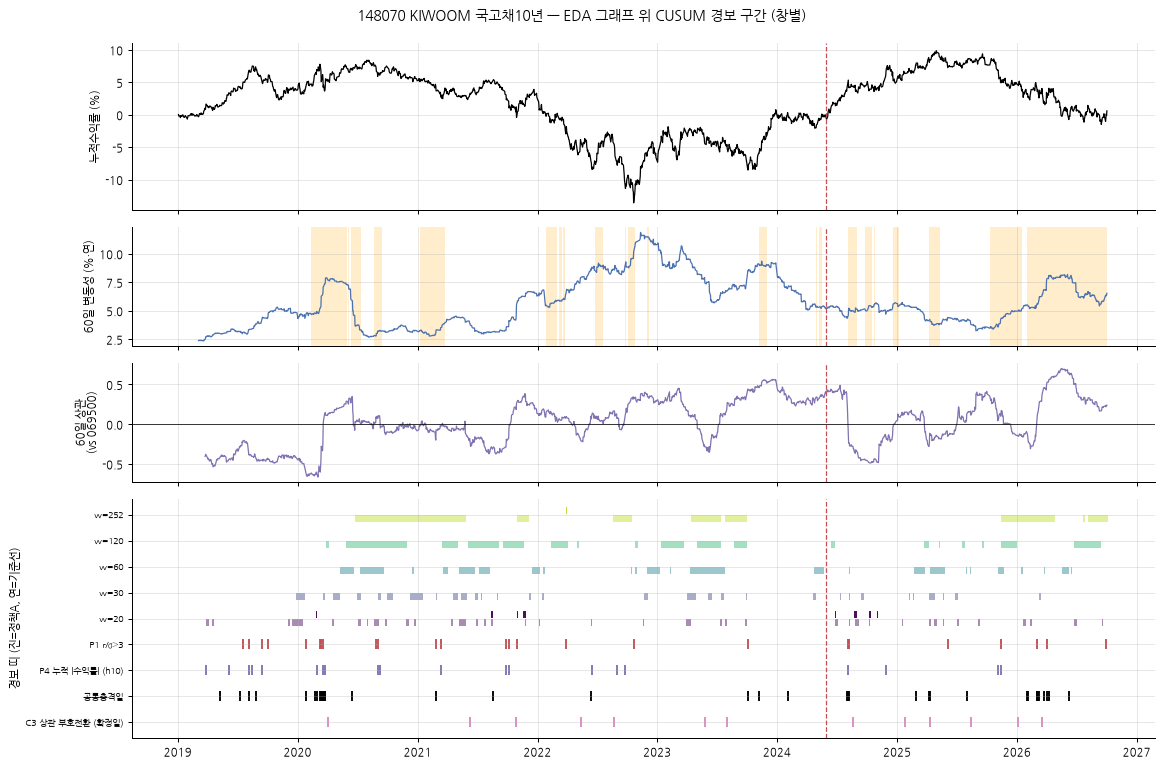

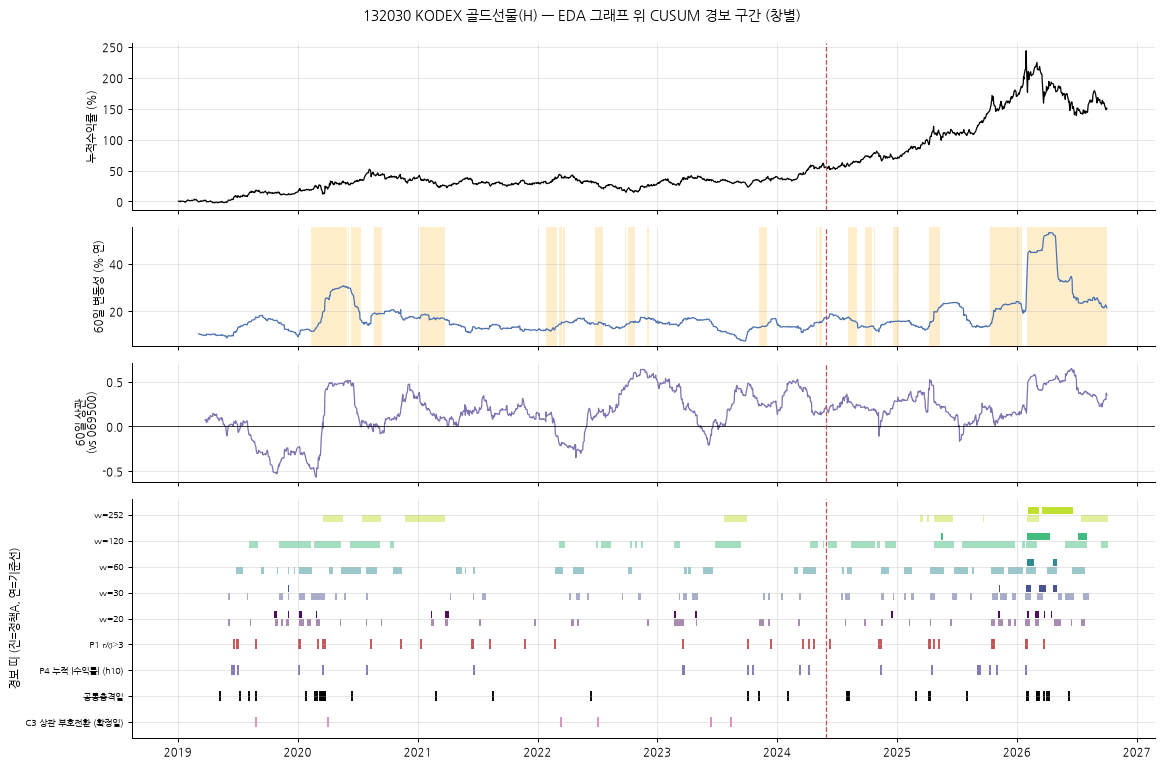

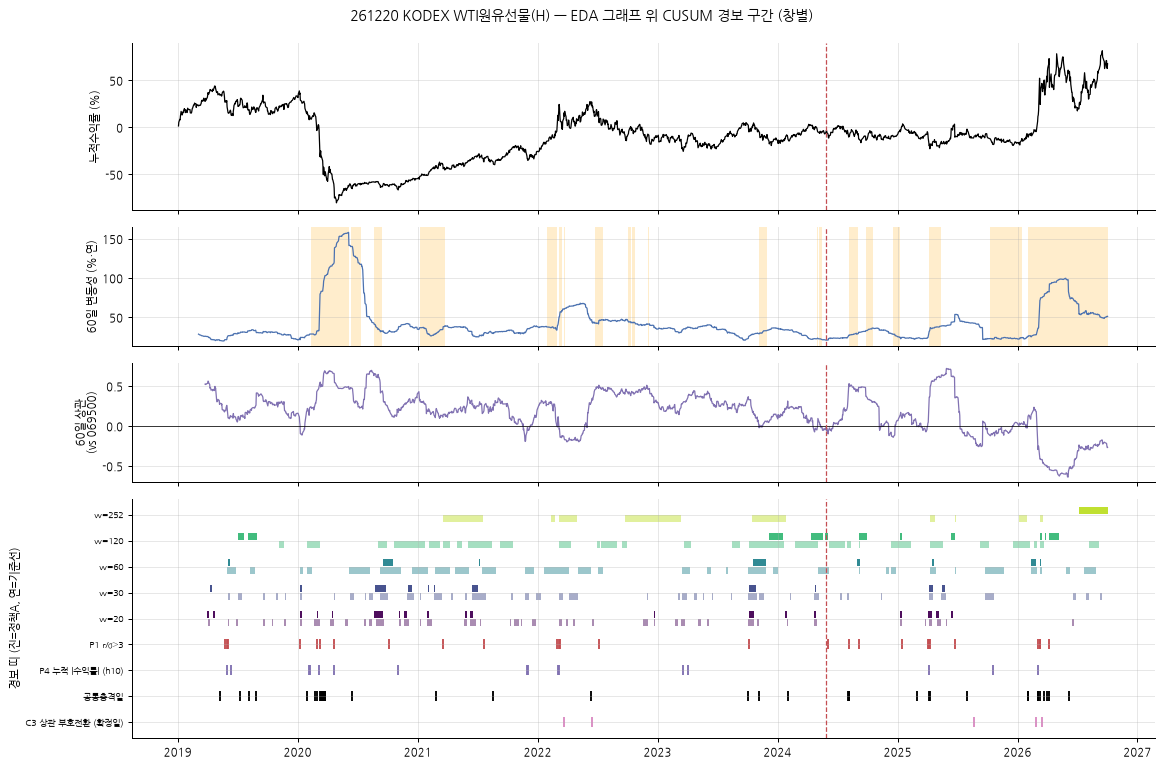

In [9]:
# 상세 4종: 주식 기준·채권·금·원유
DETAIL = ["069500", "148070", "132030", "261220"]
# 사건 기호: 종류별 색
EVC = {"P1": "#C44E52", "P4_h10": "#8172B2", "COMMON": "k", "C3": "#DA8BC3"}
# 사건 한글 이름
EVN = {"P1": "P1 r/σ≥3", "P4_h10": "P4 누적 |수익률| (h10)", "COMMON": "공통충격일", "C3": "C3 상관 부호전환 (확정일)"}
# 창별 색 (5개)
WC = dict(zip(WINDOWS, plt.cm.viridis(np.linspace(0, 0.9, len(WINDOWS))), strict=True))
# 종목마다 4단 그림
for t in DETAIL:
    # 4단 (누적수익률 / 60일 변동성 / 60일 상관 / 경보 띠)
    fig, ax = plt.subplots(4, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1, 1, 2.0]})
    # 누적수익률
    ax[0].plot(idx, (np.exp(R[t].fillna(0).cumsum() / 100) - 1) * 100, color="k", lw=1)
    # 축 이름
    ax[0].set_ylabel("누적수익률 (%)")
    # 60일 연환산 변동성
    ax[1].plot(idx, R[t].rolling(60, min_periods=40).std() * np.sqrt(252), color="#4C72B0", lw=1)
    # 축 이름
    ax[1].set_ylabel("60일 변동성 (%·연)")
    # 고변동 국면 (069500 기준, 과거만) 음영
    hv = high_vol_flag(pd.Series(np.exp(R["069500"].fillna(0).cumsum() / 100), index=idx))
    # 고변동일 음영
    ax[1].fill_between(idx, 0, 1, where=hv.to_numpy(), transform=ax[1].get_xaxis_transform(), color="orange", alpha=0.2, lw=0)
    # 60일 상관 (069500 대비) — 069500 자신이면 생략
    if t != "069500":
        # rolling 상관
        ax[2].plot(idx, R[t].rolling(60, min_periods=54).corr(R["069500"]), color="#8172B2", lw=1)
    # 0 선
    ax[2].axhline(0, color="k", lw=0.6)
    # 축 이름
    ax[2].set_ylabel("60일 상관\n(vs 069500)")
    # 경보 띠: 창마다 한 줄 (정책 A 실선, 기준선 옅게)
    for i, w in enumerate(WINDOWS):
        # 두 잔차 종류
        for rt, off, alpha in [("svrA", 0.15, 0.95), ("base", -0.15, 0.45)]:
            # 에피소드마다 가로 막대
            for e in eps.query("ticker == @t and rtype == @rt and window == @w and mask == 'none'").itertuples():
                # 막대
                ax[3].barh(i + off, pd.Timestamp(e.end) - pd.Timestamp(e.start) + pd.Timedelta(days=4), left=pd.Timestamp(e.start), height=0.28, color=WC[w], alpha=alpha)
    # 사건 기호를 띠 아래 별도 줄에 (줄마다 한 종류)
    for k, (fam, c) in enumerate(EVC.items()):
        # 그 종목의 사건 날짜
        dd = family_dates(events, fam, t)
        # 기호 (y = −1, −2, …)
        ax[3].scatter(dd, np.full(len(dd), -1.0 - k), marker="|", s=70, color=c)
    # y 축: 사건 줄 + 창 줄
    ax[3].set_yticks(list(range(-len(EVC), 0)) + list(range(len(WINDOWS))), [EVN[f] for f in reversed(EVC)] + [f"w={w}" for w in WINDOWS], fontsize=7)
    # y 범위
    ax[3].set_ylim(-len(EVC) - 0.6, len(WINDOWS) - 0.4); ax[3].set_ylabel("경보 띠 (진=정책A, 연=기준선)")
    # 분할일·2026
    for a in ax:
        # 분할
        a.axvline(SPLIT, color="#C44E52", ls="--", lw=1)
    # 제목
    fig.suptitle(f"{lab(t)} — EDA 그래프 위 CUSUM 경보 구간 (창별)", y=0.995)
    # 여백
    fig.tight_layout()
    # 저장·표시
    show(fig, f"06b_eda_detail_{t}")

**해석**

- w=60 경보 에피소드: 기준선 **577개** (2019–24 426 · 2025 85 · 2026 66), 정책 A **59개** (44 · 4 · 11). 기준선 구간은 EDA 누적수익률의 급락·급등 국면(2020-03, 2024-08, 2026)과 겹쳐 보이지만, 정책 A 구간은 드물다.
- 상세 4종: 국고채10년(148070)은 정책 A 경보가 w=60·120 에서 **0건** (w=20 8건, w=252 1건). 같은 종목의 상관 부호전환(C3)·P4 와 비교할 대상이 거의 없다. 원유(261220)는 2020 폭락 구간에서 기준선 경보가 길게 이어진다.
- 경보 띠 아래 사건 줄(P1·P4·공통충격·C3)을 보면, 경보는 사건 **당일이나 직후**에 시작하는 경우가 많다 → 선행이 아니라 반응이다 (7–8절에서 정량화).

## 7. 정합성 — Track A·EDA 사건과의 근접은 우연 이상인가 (원형 이동 귀무, BH)

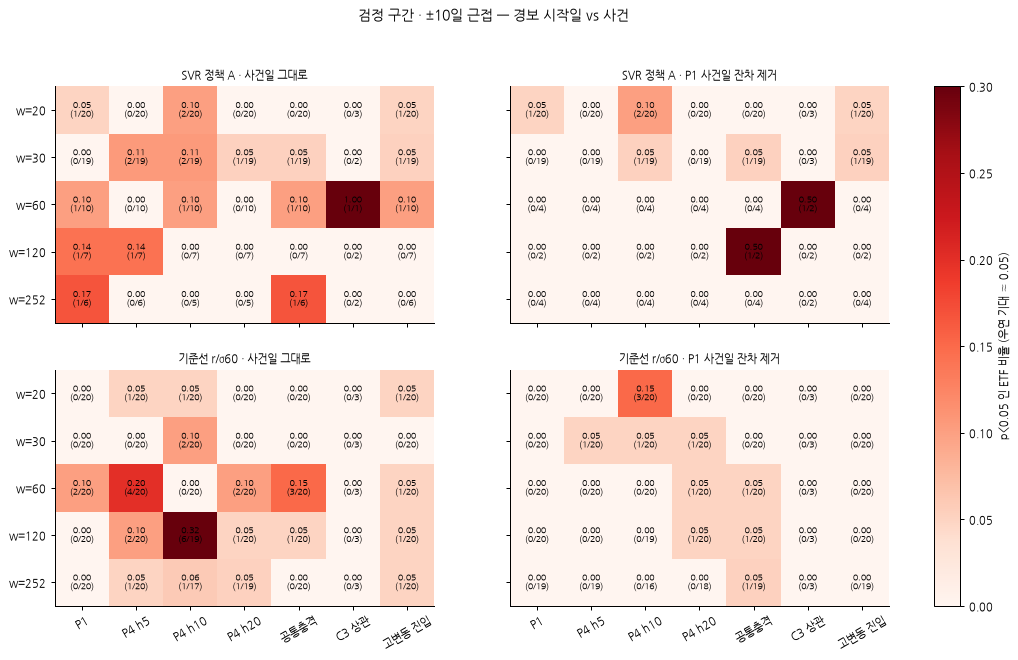

,name,family,n_episodes,n_events,precision,coverage,p_primary,q_primary
26815,261220 KODEX WTI원유선물(H),P1,4,10,0.75,0.700,0.031,0.569
25183,132030 KODEX 골드선물(H),COMMON,2,14,1.00,0.214,0.033,0.569
26863,261220 KODEX WTI원유선물(H),COMMON,4,14,0.75,0.643,0.055,0.623
16039,161510 PLUS 고배당주,COMMON,2,14,1.00,0.429,0.131,1.000
13111,143860 TIGER 헬스케어,P1,1,10,1.00,0.100,0.265,1.000
8839,091170 KODEX 은행,COMMON,1,14,1.00,0.071,0.269,1.000
7351,091230 TIGER 반도체,P1,4,10,0.50,0.100,0.272,1.000
13159,143860 TIGER 헬스케어,COMMON,1,14,1.00,0.071,0.277,1.000
20311,192090 TIGER 차이나CSI300,P1,2,10,0.50,0.600,0.398,1.000
15991,161510 PLUS 고배당주,P1,2,12,0.50,0.250,0.409,1.000


In [10]:
# 사건 종류 순서·이름
FAM = ["P1", "P4_h5", "P4_h10", "P4_h20", "COMMON", "C3", "HIVOL"]
# 사건 이름 (그림용)
FAMN = ["P1", "P4 h5", "P4 h10", "P4 h20", "공통충격", "C3 상관", "고변동 진입"]
# 2×2: (정책 A / 기준선) × (사건일 그대로 / P1 사건일 제거)
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, sharey=True)
# 칸마다
for i, rt in enumerate(["svrA", "base"]):
    # 마스크 종류
    for j, mk in enumerate(["none", "P1"]):
        # 검정 구간·L=10 에서 p<0.05 인 ETF 비율
        sub = ov.query("rtype == @rt and mask == @mk and zone == 'test' and L == 10")
        # 표: 창 × 사건
        M = sub.groupby(["window", "family"])["p_value"].apply(lambda s: (s < 0.05).sum() / s.notna().sum() if s.notna().any() else np.nan).unstack().reindex(columns=FAM)
        # 분모: 실제 검정한 ETF 수 (경보·사건이 모두 있는 경우)
        N = sub.groupby(["window", "family"])["p_value"].apply(lambda s: int(s.notna().sum())).unstack().reindex(columns=FAM)
        # 분자: p<0.05 수
        K = sub.groupby(["window", "family"])["p_value"].apply(lambda s: int((s < 0.05).sum())).unstack().reindex(columns=FAM)
        # 히트맵
        im = ax[i, j].imshow(M, cmap="Reds", vmin=0, vmax=0.3, aspect="auto")
        # 칸 숫자
        for (a, b), v in np.ndenumerate(M.to_numpy()):
            # 값 표시 (없음 = –)
            ax[i, j].text(b, a, "–" if np.isnan(v) else f"{v:.2f}\n({K.iat[a, b]}/{N.iat[a, b]})", ha="center", va="center", fontsize=7)
        # 제목
        ax[i, j].set_title(f"{'SVR 정책 A' if rt == 'svrA' else '기준선 r/σ60'} · {'사건일 그대로' if mk == 'none' else 'P1 사건일 잔차 제거'}", fontsize=9)
        # 격자 끄기
        ax[i, j].grid(False)
    # 왼쪽 축 = 창
    ax[i, 0].set_yticks(range(len(WINDOWS)), [f"w={w}" for w in WINDOWS])
# 아래 축 = 사건
for a in ax[1]:
    # 사건 이름
    a.set_xticks(range(len(FAM)), FAMN, rotation=30)
# 색 막대
fig.colorbar(im, ax=ax, fraction=0.03, label="p<0.05 인 ETF 비율 (우연 기대 ≈ 0.05)")
# 전체 제목
fig.suptitle("검정 구간 · ±10일 근접 — 경보 시작일 vs 사건", y=0.995)
# 저장·표시
show(fig, "07_consistency_heatmap")
# 1차 가족 (사전 등록, 34 검정 = KOSPI200 그룹 1건 × 17종 × 2 사건, 검정 불가 행은 p=1) 결과
ov.query("primary_family").assign(name=lambda x: x.ticker.map(lab))[["name", "family", "n_episodes", "n_events", "precision", "coverage", "p_primary", "q_primary"]].round(3).sort_values("p_primary")

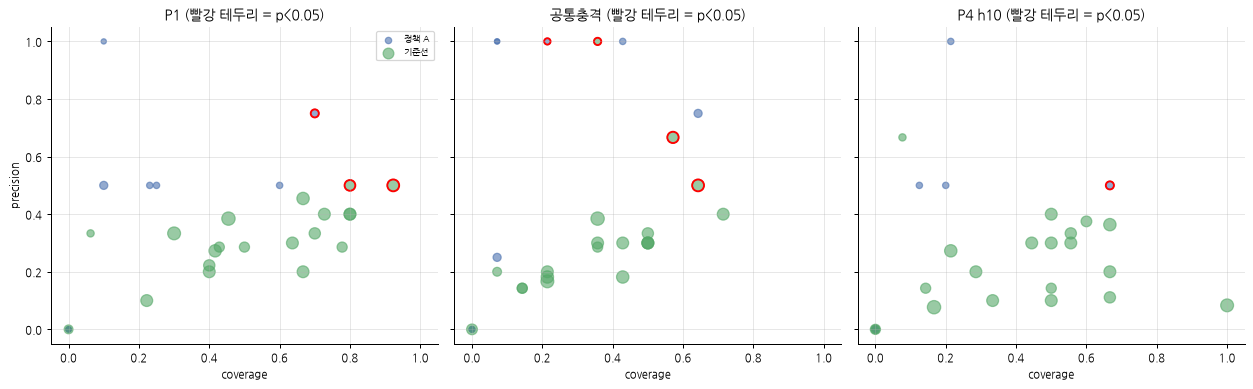

In [11]:
# precision(경보 중 사건 근처 비율) vs coverage(사건 중 경보 근처 비율) — 정책 A vs 기준선, w=60, 검정 구간
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
# 주요 사건 3종
for a, fam in zip(ax, ["P1", "COMMON", "P4_h10"], strict=True):
    # 두 잔차 종류
    for rt, c, nm in [("svrA", "#4C72B0", "정책 A"), ("base", "#55A868", "기준선")]:
        # 해당 행
        s = ov.query("rtype == @rt and mask == 'none' and zone == 'test' and L == 10 and window == 60 and family == @fam")
        # 점 크기 = 에피소드 수
        a.scatter(s.coverage, s.precision, s=10 + 8 * s.n_episodes, color=c, alpha=0.6, label=nm)
        # p<0.05 강조 (테두리)
        sig = s[s.p_value < 0.05]
        # 테두리 점
        a.scatter(sig.coverage, sig.precision, s=10 + 8 * sig.n_episodes, facecolors="none", edgecolors="r", lw=1.5)
    # 제목·축
    a.set_title(f"{dict(zip(FAM, FAMN, strict=True))[fam]} (빨강 테두리 = p<0.05)"); a.set_xlabel("coverage")
# 축 이름·범례
ax[0].set_ylabel("precision"); ax[0].legend(fontsize=7)
# 여백
fig.tight_layout()
# 저장·표시
show(fig, "07b_precision_coverage")

**해석**

- 전체 탐색 23,442 검정의 p<0.05 비율은 **5.9%** (우연 기대 5%), global BH q<0.10 은 283개 (탐색용 — 검정 간 강한 의존, 대부분 in-sample 적합 구간).
- **사전 등록 1차 가족** (정책 A · w=60 · 검정 구간 · P1+공통충격 · ±10일; KOSPI200 그룹 4종은 069500 1건, 경보가 없어 검정할 수 없는 행은 p=1 → **34 검정**): p<0.05 **2개** (261220 P1 p=0.031 · 132030 공통충격 p=0.033, 둘 다 에피소드 2–4개), **최소 q=0.57 → 우연 이상이라는 증거 없음**.
- 기계적 성분: 그 ETF 의 P1 사건일 잔차를 지우면 p<0.05 비율이 기준선 8.9%→**4.6%**, 정책 A 6.6%→**2.6%** 로 떨어진다. 2026 을 뺀 검정 구간도 기준선 6.2% · 정책 A 3.5%. → 남는 겹침은 '같은 날 큰 수익률' 과 2026 기저율 영향이 크다 (Track A 와 같은 결론).
- P1 은 기준선과 같은 점수(r/σ60≥3)로 정의되어 있어, 기준선의 P1 근접은 일부 기계적으로 유리하다 — 사건일 제거 행을 함께 봐야 한다.
- C3 칸의 큰 비율은 검정이 1–3개뿐인 칸이다 (괄호 안 분모). 일반화하지 않는다.
- **검정 구간 정의**: 창 전체가 검정 구간 안에 들어간 날(분할일 + w − 1)부터. 창이 두 구간에 걸친 경보는 `boundary` 로 따로 표시했다 (w=60: 정책 A 5 · 기준선 18 에피소드).

## 8. 유의 경보일 때 어떤 흐름이 겹치나 — 흐름 조합과 대표 에피소드

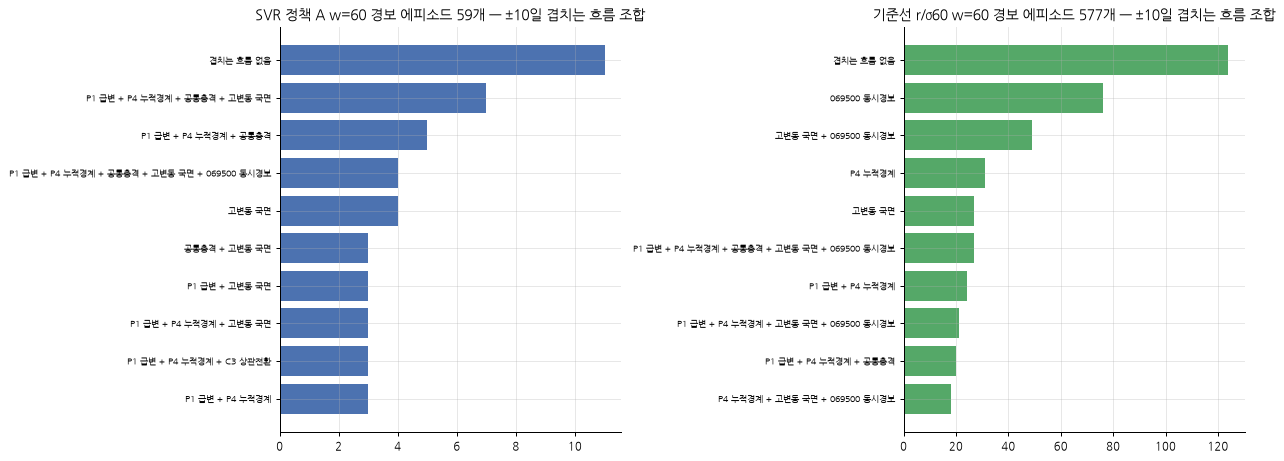

P1 급변  P4 누적경계  공통충격  C3 상관전환  고변동 국면  069500 동시경보
rtype zone                                                        
base  boundary   0.37     0.41  0.35     0.01    0.23         0.24
      fit        0.23     0.39  0.23     0.02    0.24         0.45
      test       0.31     0.39  0.32     0.02    0.61         0.53
svrA  boundary   0.80     0.80  0.60     0.00    0.80         0.40
      fit        0.30     0.47  0.30     0.04    0.31         0.22
      test       0.42     0.50  0.46     0.03    0.67         0.22

In [12]:
# 흐름 플래그 열
FL = ["P1", "P4", "COMMON", "C3", "HIVOL", "KOSPI200_sync"]
# 흐름 한글 이름
FLN = {"P1": "P1 급변", "P4": "P4 누적경계", "COMMON": "공통충격", "C3": "C3 상관전환", "HIVOL": "고변동 국면", "KOSPI200_sync": "069500 동시경보"}
# w=60 에피소드만
f60 = flows.query("window == 60").copy()
# 조합 문자열 ("없음" = 아무 흐름도 없음)
f60["combo"] = f60[FL].apply(lambda r: " + ".join(FLN[c] for c in FL if r[c]) or "겹치는 흐름 없음", axis=1)
# 2단: 조합 막대 (정책 A / 기준선)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
# 잔차 종류마다
for a, (rt, c, nm) in zip(ax, [("svrA", "#4C72B0", "SVR 정책 A"), ("base", "#55A868", "기준선 r/σ60")], strict=True):
    # 상위 10개 조합
    vc = f60.query("rtype == @rt")["combo"].value_counts().head(10)[::-1]
    # 가로 막대
    a.barh(range(len(vc)), vc.to_numpy(), color=c)
    # 라벨
    a.set_yticks(range(len(vc)), vc.index, fontsize=7)
    # 제목
    a.set_title(f"{nm} w=60 경보 에피소드 {int((f60.rtype == rt).sum())}개 — ±10일 겹치는 흐름 조합")
# 여백
fig.tight_layout()
# 저장·표시
show(fig, "08a_flow_combinations")
# 흐름별 비율 (정책·구간별)
flows.groupby(["rtype", "zone"])[FL].mean().round(2).rename(columns=FLN)

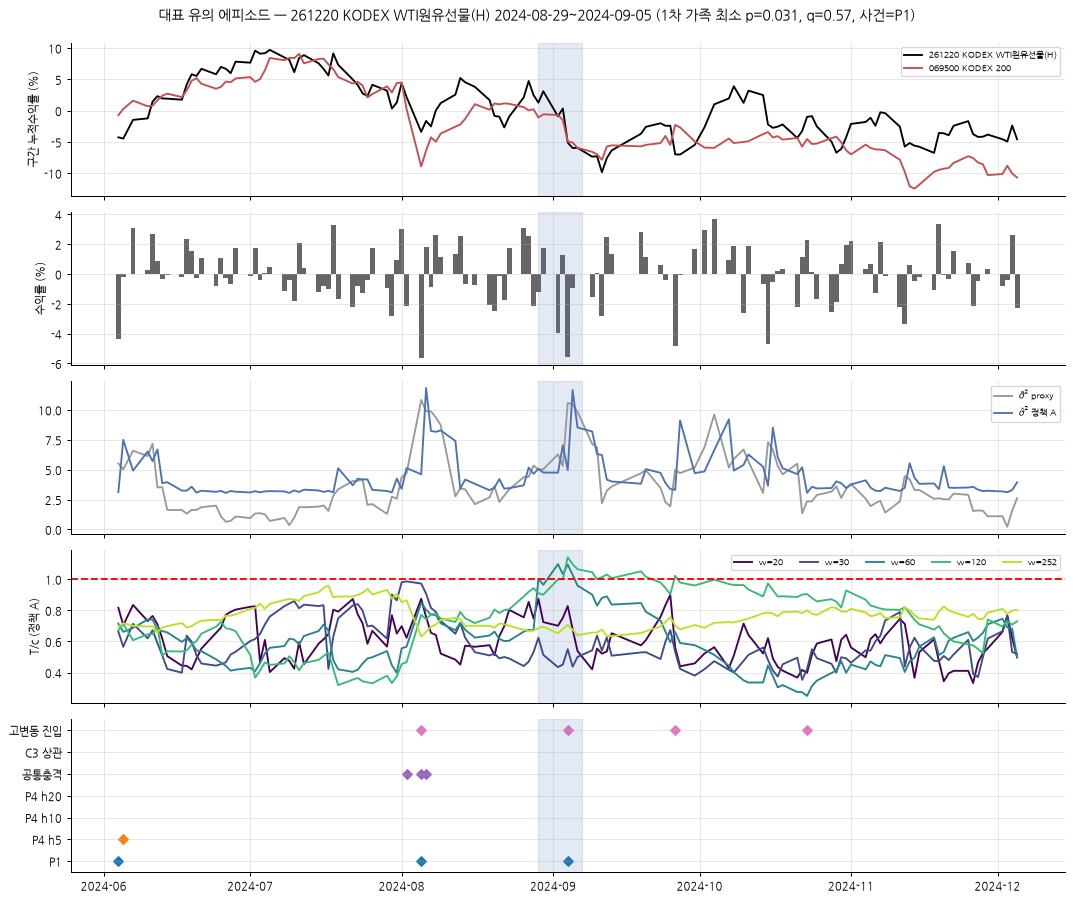

In [13]:
# 대표 에피소드 = 1차 가족에서 p 가 가장 작은 ETF 의 검정 구간 첫 경보 (사전 규칙으로 자동 선택)
best = ov.query("primary_family").sort_values("p_primary").iloc[0]
# 그 ETF
TE = best.ticker
# 그 ETF 의 검정 구간 w=60 정책 A 에피소드
E = eps.query("ticker == @TE and rtype == 'svrA' and window == 60 and mask == 'none' and zone == 'test'").iloc[0]
# 앞뒤 60거래일 범위
lo, hi = idx.get_loc(pd.Timestamp(E.start)) - 60, idx.get_loc(pd.Timestamp(E.end)) + 60
# 구간 날짜
dd = idx[max(lo, 0) : min(hi, len(idx) - 1)]
# 5단 정렬 패널
fig, ax = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
# (1) 그 ETF·069500 누적수익률 (구간 시작=0)
for t, c in [(TE, "k"), ("069500", "#C44E52")]:
    # 구간 누적
    ax[0].plot(dd, (np.exp(R[t].loc[dd].fillna(0).cumsum() / 100) - 1) * 100, color=c, label=lab(t))
# 범례·축
ax[0].legend(fontsize=7); ax[0].set_ylabel("구간 누적수익률 (%)")
# (2) 수익률
ax[1].bar(dd, R[TE].loc[dd], width=1, color="0.4"); ax[1].set_ylabel("수익률 (%)")
# (3) proxy vs σ̂² (정책 A)
ax[2].plot(dd, pd.Series(st[f"proxy__{TE}"], index=idx).loc[dd], color="0.6", label=r"$\tilde{\sigma}^2$ proxy")
# 정책 A
ax[2].plot(dd, pd.Series(st[f"varA__{TE}"], index=idx).loc[dd], color="#4C72B0", label=r"$\hat{\sigma}^2$ 정책 A"); ax[2].legend(fontsize=7)
# (4) 이동창 T/c (모든 창)
for w in WINDOWS:
    # 임계값
    cw = crit.query("ticker == @TE and rtype == 'svrA' and window == @w")["c_bootstrap"].iloc[0]
    # 곡선
    ax[3].plot(dd, roll[f"{TE}|svrA|{w}"].loc[dd] / cw, color=WC[w], label=f"w={w}")
# 기준선·범례
ax[3].axhline(1, color="r", ls="--"); ax[3].legend(fontsize=7, ncol=5); ax[3].set_ylabel("T/c (정책 A)")
# (5) 겹치는 흐름 기호
for k, fam in enumerate(["P1", "P4_h5", "P4_h10", "P4_h20", "COMMON", "C3", "HIVOL"]):
    # 사건 날짜 중 구간 안
    x = family_dates(events, fam, TE)
    # 구간 필터
    x = x[(x >= dd[0]) & (x <= dd[-1])]
    # 기호
    ax[4].scatter(x, np.full(len(x), k), marker="D", s=30)
# 축 이름
ax[4].set_yticks(range(7), FAMN); ax[4].set_ylim(-0.5, 6.5)
# 에피소드 음영 (모든 패널)
for a in ax:
    # 음영
    a.axvspan(pd.Timestamp(E.start), pd.Timestamp(E.end) + pd.Timedelta(days=2), color="#4C72B0", alpha=0.15)
# 제목
fig.suptitle(f"대표 유의 에피소드 — {lab(TE)} {E.start}~{E.end} (1차 가족 최소 p={best.p_primary:.3f}, q={best.q_primary:.2f}, 사건={best.family})", y=0.995)
# 여백
fig.tight_layout()
# 저장·표시
show(fig, "08b_representative_episode")

**해석**

- 정책 A w=60 에피소드 59개 중 ±10일 안에 **P1 59% · P4 53% · 공통충격 46% · 고변동 국면 49% · C3 10% · 069500 동시 7%**, 아무 흐름도 없는 것 19% (11개, 가장 흔함). 그다음 조합이 'P1 + P4 + 공통충격 + 고변동' (7개)·'P1 + P4 + 공통충격' (5개) — 정책 A 가 드물게 울릴 때는 대개 **충격 그 자체**에 반응한 것이다.
- 기준선 577개: P1 29% · P4 41% · 공통충격 25% · 고변동 37% · **069500 동시 46%** · 흐름 없음 21% — 시장 전체 변동성 국면이 여러 ETF 에 동시에 경보를 만든다.
- 대표 에피소드 (1차 가족 최소 p, 사전 규칙으로 자동 선택): **261220 WTI원유 2024-08-29~09-05**. 2024-08 세계 급락 직후 |수익률| 2–4% 날이 이어진 변동성 군집(08-26 |r|>3%) 속에서 w=60 이 08-29, w=120 이 09-04 에 경보를 켠다. 같은 군집의 P1(−, 09-04)보다 4거래일 빠르지만, 군집이 이미 시작된 뒤라 **새 국면의 조기경보라기보다 진행 중인 충격에 대한 반응**이다.

## 9. 채권 ↔ KOSPI — CUSUM 구간 vs C3 상관 전환 vs P4 누적수익률 절대값 경계

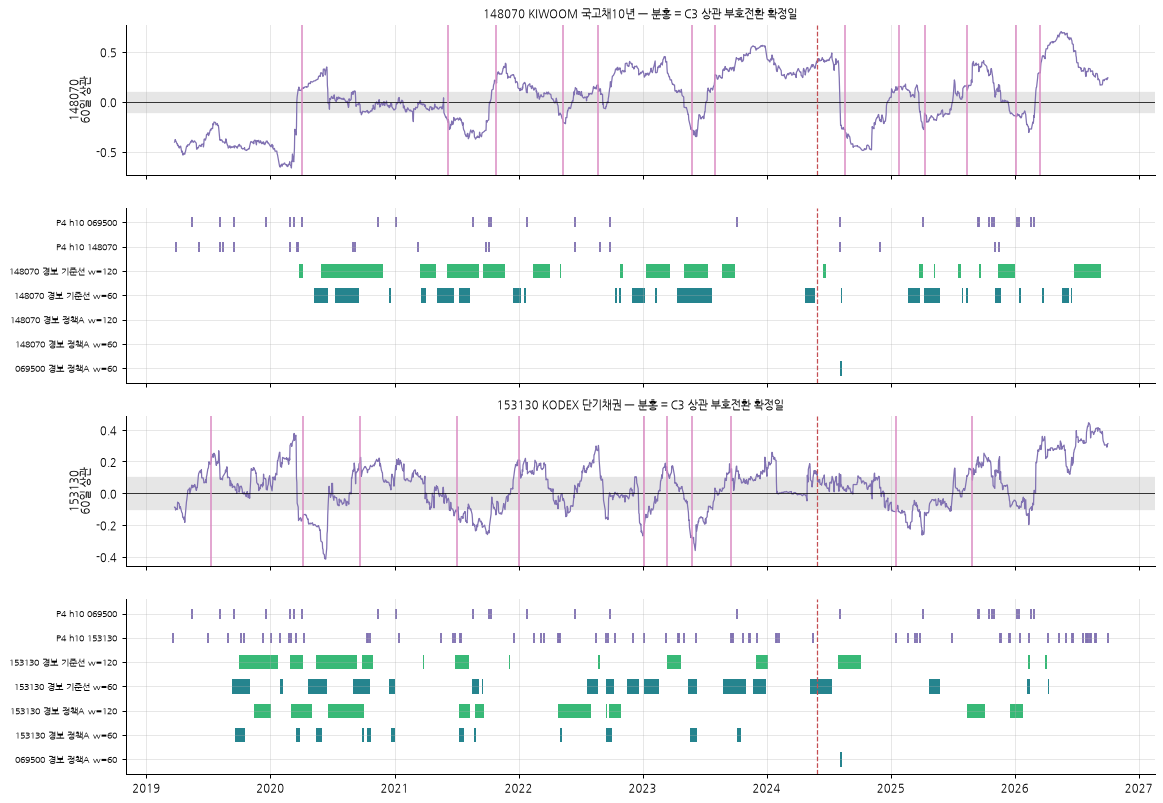

,ticker,rtype,window,family,zone,n_episodes,n_events,precision,coverage,p_value
21769,148070,svrA,60,P1,all,0,25,NaN,0.000,NaN
21775,148070,svrA,60,P1,test,0,5,NaN,0.000,NaN
21793,148070,svrA,60,P4_h10,all,0,20,NaN,0.000,NaN
21799,148070,svrA,60,P4_h10,test,0,3,NaN,0.000,NaN
21829,148070,svrA,60,C3,all,0,13,NaN,0.000,NaN
21835,148070,svrA,60,C3,test,0,5,NaN,0.000,NaN
21853,148070,svrA,120,P1,all,0,25,NaN,0.000,NaN
21859,148070,svrA,120,P1,test,0,5,NaN,0.000,NaN
21877,148070,svrA,120,P4_h10,all,0,20,NaN,0.000,NaN
21883,148070,svrA,120,P4_h10,test,0,3,NaN,0.000,NaN


In [14]:
# 대상: 국고채10년·단기채권 (vs 069500)
BONDS = ["148070", "153130"]
# 2개 종목 × 1 그림 (행: 상관, 띠)
fig, ax = plt.subplots(4, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.4, 1.2, 1.4]})
# 종목마다 2행씩
for b, t in enumerate(BONDS):
    # 상관 행 위치
    a = ax[2 * b]
    # 60일 상관 (vs 069500)
    a.plot(idx, R[t].rolling(60, min_periods=54).corr(R["069500"]), color="#8172B2", lw=1)
    # 0 선·band ±0.1
    a.axhline(0, color="k", lw=0.6); a.axhspan(-0.1, 0.1, color="0.9")
    # C3 확정일
    for d0 in family_dates(events, "C3", t):
        # 세로선
        a.axvline(d0, color="#DA8BC3", lw=1.2)
    # 축 이름
    a.set_ylabel(f"{t}\n60일 상관"); a.set_title(f"{lab(t)} — 분홍 = C3 상관 부호전환 확정일", fontsize=9)
    # 띠 행
    a2 = ax[2 * b + 1]
    # 줄 정의: (이름, 데이터)
    rows = [("069500 경보 정책A w=60", "069500", "svrA", 60), (f"{t} 경보 정책A w=60", t, "svrA", 60), (f"{t} 경보 정책A w=120", t, "svrA", 120), (f"{t} 경보 기준선 w=60", t, "base", 60), (f"{t} 경보 기준선 w=120", t, "base", 120)]
    # 경보 띠
    for i, (nm, tk, rt, w) in enumerate(rows):
        # 에피소드 막대
        for e in eps.query("ticker == @tk and rtype == @rt and window == @w and mask == 'none'").itertuples():
            # 막대
            a2.barh(i, pd.Timestamp(e.end) - pd.Timestamp(e.start) + pd.Timedelta(days=4), left=pd.Timestamp(e.start), color=WC[w], height=0.6)
    # P4 누적 경계 (그 채권·069500, h10)
    for j, tk in enumerate([t, "069500"]):
        # 날짜
        x = family_dates(events, "P4_h10", tk)
        # 기호
        a2.scatter(x, np.full(len(x), len(rows) + j), marker="|", s=60, color="#8172B2")
    # 축 이름
    a2.set_yticks(range(len(rows) + 2), [r[0] for r in rows] + [f"P4 h10 {t}", "P4 h10 069500"], fontsize=7); a2.set_ylim(-0.6, len(rows) + 1.6)
# 분할일
for a in ax:
    # 세로선
    a.axvline(SPLIT, color="#C44E52", ls="--", lw=1)
# 여백
fig.tight_layout()
# 저장·표시
show(fig, "09_bond_vs_kospi")
# 채권 2종의 C3/P4 근접 지표 (검정·전 구간, L=10)
ov.query("ticker in @BONDS and mask == 'none' and L == 10 and window in [60, 120] and family in ['C3', 'P4_h10', 'P1'] and zone in ['all', 'test']")[["ticker", "rtype", "window", "family", "zone", "n_episodes", "n_events", "precision", "coverage", "p_value"]].round(3)

**해석**

- 148070 국고채10년: 정책 A 경보가 w=60 에서 0건이라 C3·P4 와 비교할 수 없다. 기준선 w=60 (24 에피소드) vs C3 (13 확정): coverage 0.39 · precision 0.21 · **p=0.23**, vs P4 h10 p=0.83 — 우연 이상 아님.
- 153130 단기채권: 정책 A w=60 vs P1 (전 구간) p=0.007 · vs C3 p=0.037 이지만 **둘 다 적합 구간(in-sample)에서만** 나온 것이다 — 검정 구간에는 경보 에피소드가 0건이다. P1 적합 구간 q_global=0.043 (탐색). out-of-sample 근거는 없다.
- 해석: CUSUM-of-squares 는 **변동성 구조**, C3 는 **상관 부호 국면**, P4 는 **누적수익률 절대값 경계**를 잰다. 세 경계는 서로 다른 것을 재며, 이 데이터의 검정 구간에서 우연 이상 겹치지 않는다.

## 10. 달력연도 블록 — ETF × 연도 사후 CUSUM ("연" 의 두 번째 해석)

findfont: Failed to find font weight bold for NanumGothic, now using 600.


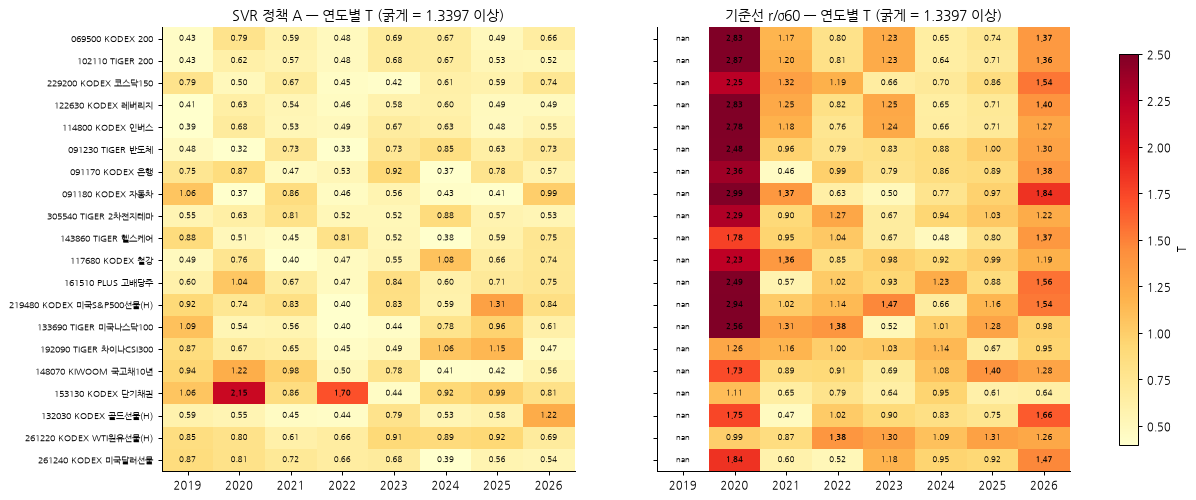

year,2019,2020,2021,2022,2023,2024,2025,2026
rtype,,,,,,,,
base,0.0,0.85,0.1,0.10,0.05,0.0,0.05,0.55
svrA,0.0,0.05,0.0,0.05,0.00,0.0,0.00,0.00


In [15]:
# 2단: 정책 A / 기준선
fig, ax = plt.subplots(1, 2, figsize=(14, 6.4), sharey=True)
# 잔차 종류마다
for a, (rt, nm) in zip(ax, [("svrA", "SVR 정책 A"), ("base", "기준선 r/σ60")], strict=True):
    # ETF × 연도 표
    M = years.query("rtype == @rt").pivot(index="ticker", columns="year", values="T").loc[TICKERS]
    # 히트맵
    im = a.imshow(M, cmap="YlOrRd", vmin=0.4, vmax=2.5, aspect="auto")
    # 칸 숫자 (임계 이상은 굵게)
    for (i, j), v in np.ndenumerate(M.to_numpy()):
        # 표시
        a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, fontweight="bold" if v >= 1.3397 else "normal")
    # 축
    a.set_xticks(range(M.shape[1]), M.columns); a.set_title(f"{nm} — 연도별 T (굵게 = 1.3397 이상)"); a.grid(False)
# y 축 이름
ax[0].set_yticks(range(len(TICKERS)), [lab(t) for t in TICKERS], fontsize=7)
# 색 막대
fig.colorbar(im, ax=ax, fraction=0.02, label="T")
# 저장·표시
show(fig, "10_yearly_blocks")
# 연도별 기각 비율
years.groupby(["rtype", "year"])["reject_asymptotic"].mean().unstack().round(2)

**해석**

- 기준선 연도 블록 기각 비율: **2020 85%** · 2026 55% · 2021·2022 10% · 나머지 ≤5% (2019 은 60일 warm-up 으로 계산 불가). EDA 의 고변동 해(2020 코로나, 2026)와 정확히 맞는다 → 기준선 CUSUM 은 '그 해 안에서 변동성이 바뀌었는가' 를 잘 요약한다.
- 정책 A 는 2020 5% · 2022 5% 외에는 0% — 연 단위에서도 변동성 변화를 흡수한다.

## 11. 종합 — 수치 고정 확인과 결론

In [16]:
# 핵심 수치 (README 와 같은 값이어야 한다)
summary = {
    # 사후 검정 기각 수 (정책별)
    "기각_정책A": int(full.query("policy == 'A'")["reject"].sum()),
    # 정책 B
    "기각_정책B": int(full.query("policy == 'B'")["reject"].sum()),
    # 기준선
    "기각_기준선": int(full.query("policy == 'base'")["reject"].sum()),
    # w=60 연간 경보 에피소드 (관측/귀무) — 정책 A
    "w60_정책A_관측/귀무": tuple(nul.query("rtype == 'svrA' and window == 60")[["observed_episodes_per_year", "null_episodes_per_year"]].mean().round(2)),
    # 기준선
    "w60_기준선_관측/귀무": tuple(nul.query("rtype == 'base' and window == 60")[["observed_episodes_per_year", "null_episodes_per_year"]].mean().round(2)),
    # 1차 가족 검정 수·p<0.05·q<0.10
    "1차가족_n/p05/q10": (int(ov.primary_family.sum()), int((ov.query("primary_family").p_primary < 0.05).sum()), int((ov.query("primary_family").q_primary < 0.10).sum())),
}
# 표로 보기
pd.Series(summary, name="값").to_frame()

,값
기각_정책A,2
기각_정책B,9
기각_기준선,1
w60_정책A_관측/귀무,"(0.39, 1.71)"
w60_기준선_관측/귀무,"(3.82, 1.7)"
1차가족_n/p05/q10,"(34, 2, 0)"


**결론 — 재현·적용 가능성**

| 항목 | 판정 |
|---|---|
| 재현성 | ✅ 오토런 독립 2회 결과표 9종 **바이트 동일** · 노트북 2회 출력 동일 · 독립 검토(누수·통계식) 후 1차 가족 크기·KOSPI 그룹·검정 구간 경계 정정 반영 |
| 원문 대비 | ⚠️ Track B 판정 그대로 METHOD_FIDELITY_UNRESOLVED — 이 결과는 ETF 적용 민감도 분석 |
| SVR–GARCH 정책 A CUSUM 을 급등 탐지에 | ❌ 변동성 변화를 흡수해 경보율이 iid 기준값보다 낮고(w=60 0.39 vs 1.71/년), 사건 근접도 우연 수준(1차 가족 34 검정, 최소 q 0.57) |
| 정책 B | ⚠️ 기각 9/20 로 A 와 크게 다름 — 원문 미명시 선택에 결과가 좌우됨 |
| 기준선 r/σ60 CUSUM | ⚠️ 변동성 국면(2020·2026)은 잘 요약하나, 급등 사건과의 근접은 기계적 성분 제거 후 우연 수준 — 방향이 없는 '국면 맥락' 지표로만 |
| Track A 경계(C3·P4)와 정합성 | ❌ 우연 이상 겹침 없음 — 서로 다른 것을 잰다 |
| 다음 단계 (W04) | 제곱(분산) CUSUM 대신 **평균·방향 CUSUM**(R2H `PageCUSUM` 류)을 승인된 정답(D-01)으로 평가 · 변동성 CUSUM 은 맥락 변수로 · 정책 A/B 병기 · grid 경계(ε=0.1) 민감도 |